In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 120)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
if not os.path.exists("matches.csv") or not os.path.exists("deliveries.csv"):
    raise FileNotFoundError(
        "Place matches.csv and deliveries.csv beside this notebook. "
        "Download them from the Kaggle dataset linked in the introduction."
    )

matches = pd.read_csv("matches.csv")
deliveries = pd.read_csv("deliveries.csv")

print("Matches shape:", matches.shape)
print("Deliveries shape:", deliveries.shape)
display(matches.head())
display(deliveries.head())

Matches shape: (1095, 20)
Deliveries shape: (260920, 17)


,id,season,city,date,match_type,player_of_match,venue,team1,team2,toss_winner,toss_decision,winner,result,result_margin,target_runs,target_overs,super_over,method,umpire1,umpire2
0,335982,2007/08,Bangalore,2008-04-18,League,BB McCullum,M Chinnaswamy Stadium,Royal Challengers Bangalore,Kolkata Knight Riders,Royal Challengers Bangalore,field,Kolkata Knight Riders,runs,140.0,223.0,20.0,N,NaN,Asad Rauf,RE Koertzen
1,335983,2007/08,Chandigarh,2008-04-19,League,MEK Hussey,"Punjab Cricket Association Stadium, Mohali",Kings XI Punjab,Chennai Super Kings,Chennai Super Kings,bat,Chennai Super Kings,runs,33.0,241.0,20.0,N,NaN,MR Benson,SL Shastri
2,335984,2007/08,Delhi,2008-04-19,League,MF Maharoof,Feroz Shah Kotla,Delhi Daredevils,Rajasthan Royals,Rajasthan Royals,bat,Delhi Daredevils,wickets,9.0,130.0,20.0,N,NaN,Aleem Dar,GA Pratapkumar
3,335985,2007/08,Mumbai,2008-04-20,League,MV Boucher,Wankhede Stadium,Mumbai Indians,Royal Challengers Bangalore,Mumbai Indians,bat,Royal Challengers Bangalore,wickets,5.0,166.0,20.0,N,NaN,SJ Davis,DJ Harper
4,335986,2007/08,Kolkata,2008-04-20,League,DJ Hussey,Eden Gardens,Kolkata Knight Riders,Deccan Chargers,Deccan Chargers,bat,Kolkata Knight Riders,wickets,5.0,111.0,20.0,N,NaN,BF Bowden,K Hariharan


,match_id,inning,batting_team,bowling_team,over,ball,batter,bowler,non_striker,batsman_runs,extra_runs,total_runs,extras_type,is_wicket,player_dismissed,dismissal_kind,fielder
0,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,1,SC Ganguly,P Kumar,BB McCullum,0,1,1,legbyes,0,NaN,NaN,NaN
1,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,2,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
2,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,3,BB McCullum,P Kumar,SC Ganguly,0,1,1,wides,0,NaN,NaN,NaN
3,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,4,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN
4,335982,1,Kolkata Knight Riders,Royal Challengers Bangalore,0,5,BB McCullum,P Kumar,SC Ganguly,0,0,0,NaN,0,NaN,NaN,NaN


In [3]:
print("Missing values in matches:")
display(matches.isnull().sum().sort_values(ascending=False).head(10))
print("Missing values in deliveries:")
display(deliveries.isnull().sum().sort_values(ascending=False).head(10))

matches = matches.drop_duplicates()
deliveries = deliveries.drop_duplicates()

print("Shapes after removing duplicate rows:")
print("Matches:", matches.shape)
print("Deliveries:", deliveries.shape)

required_match_cols = {"id", "season", "winner", "team1", "team2"}
required_delivery_cols = {"match_id", "batter", "batsman_runs", "total_runs", "batting_team"}
if not required_match_cols.issubset(matches.columns):
    raise ValueError(f"Unexpected matches.csv schema. Expected columns include: {required_match_cols}")
if not required_delivery_cols.issubset(deliveries.columns):
    raise ValueError(f"Unexpected deliveries.csv schema. Expected columns include: {required_delivery_cols}")

Missing values in matches:


method             1074
city                 51
result_margin        19
player_of_match       5
winner                5
target_runs           3
target_overs          3
id                    0
date                  0
season                0
dtype: int64

Missing values in deliveries:


fielder             251566
dismissal_kind      247970
player_dismissed    247970
extras_type         246795
match_id                 0
inning                   0
batting_team             0
bowling_team             0
over                     0
non_striker              0
dtype: int64

Shapes after removing duplicate rows:
Matches: (1095, 20)
Deliveries: (260920, 17)


,matches_played
season,
2007/08,58
2009,57
2009/10,60
2011,73
2012,74
2013,76
2014,60
2015,59
2016,60


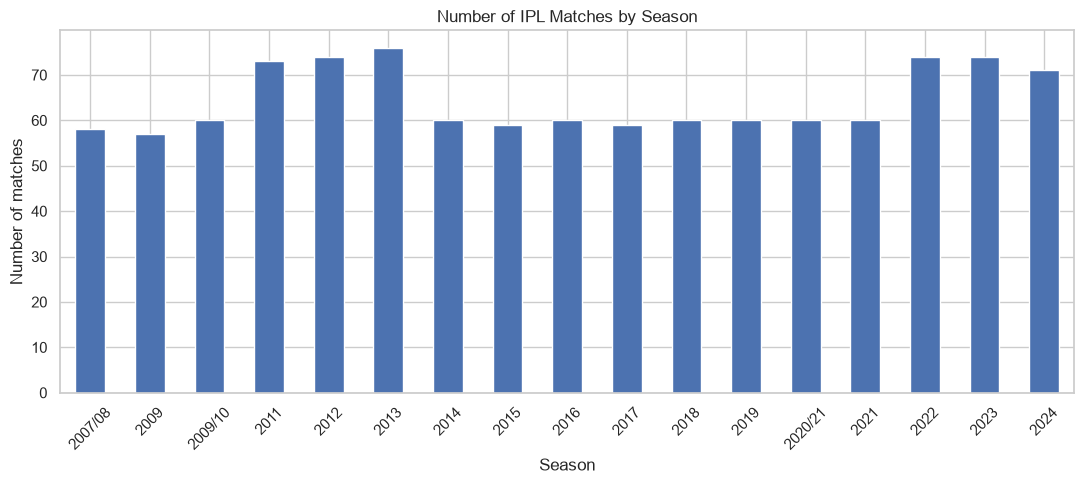

,wins
winner,
Mumbai Indians,144
Chennai Super Kings,138
Kolkata Knight Riders,131
Royal Challengers Bangalore,116
Rajasthan Royals,112
Kings XI Punjab,88
Sunrisers Hyderabad,88
Delhi Daredevils,67
Delhi Capitals,48


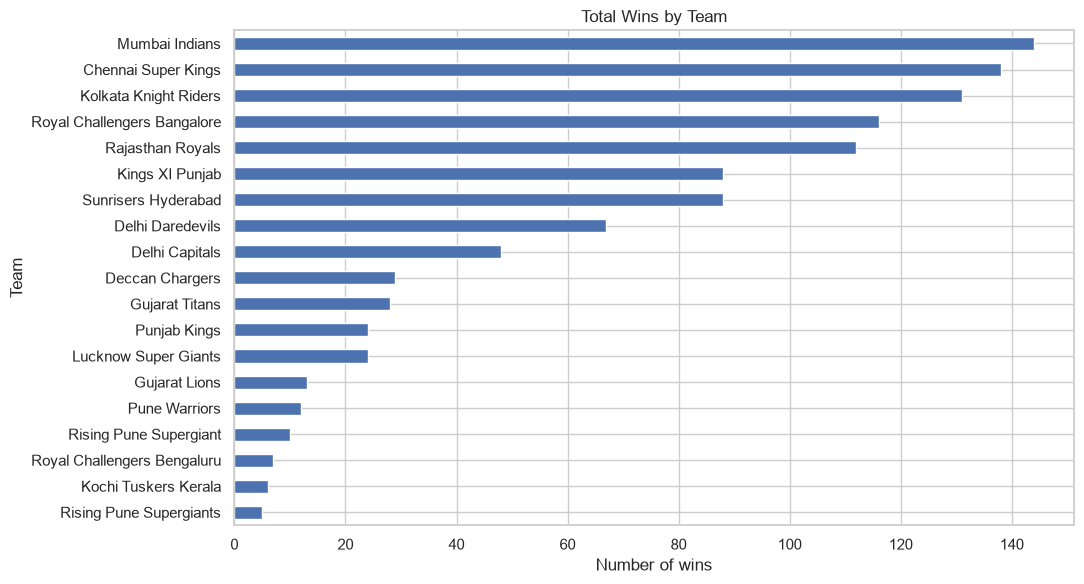

In [4]:
season_col = "season"
season_counts = matches.groupby(season_col).size().sort_index()
display(season_counts.rename("matches_played").to_frame())

plt.figure(figsize=(11, 5))
season_counts.plot(kind="bar")
plt.title("Number of IPL Matches by Season")
plt.xlabel("Season")
plt.ylabel("Number of matches")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

team_wins = matches["winner"].dropna().value_counts()
display(team_wins.rename("wins").to_frame())

plt.figure(figsize=(11, 6))
team_wins.sort_values().plot(kind="barh")
plt.title("Total Wins by Team")
plt.xlabel("Number of wins")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

,batter,runs
0,V Kohli,8014
1,S Dhawan,6769
2,RG Sharma,6630
3,DA Warner,6567
4,SK Raina,5536
5,MS Dhoni,5243
6,AB de Villiers,5181
7,CH Gayle,4997
8,RV Uthappa,4954
9,KD Karthik,4843


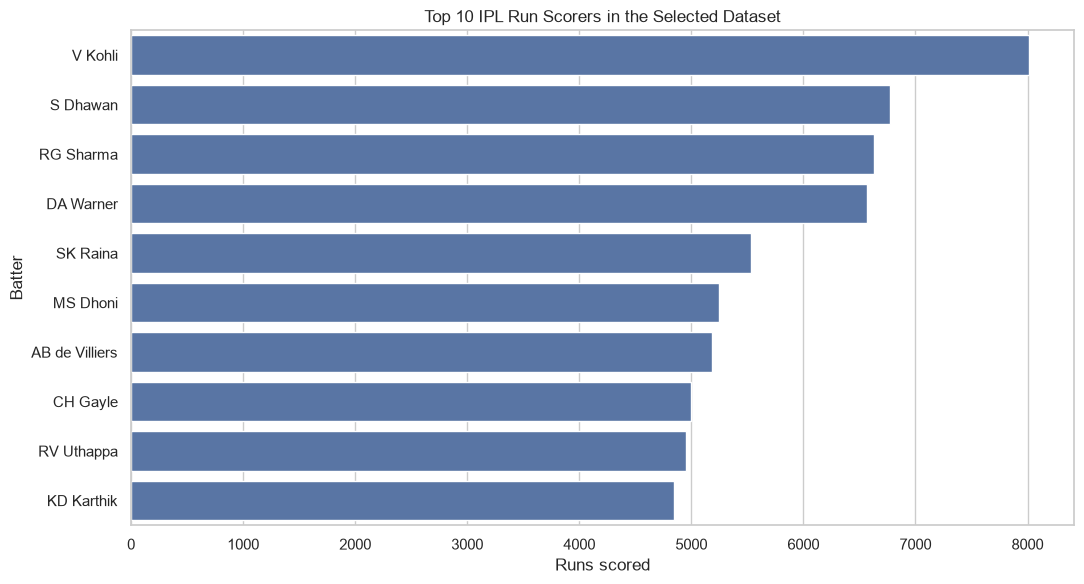

,runs,balls_faced_approx,strike_rate_approx
batter,,,
V Kohli,8014,6051,132.44
S Dhawan,6769,5304,127.62
RG Sharma,6630,5039,131.57
DA Warner,6567,4682,140.26
SK Raina,5536,4025,137.54
MS Dhoni,5243,3790,138.34
AB de Villiers,5181,3400,152.38
CH Gayle,4997,3331,150.02
RV Uthappa,4954,3784,130.92


In [5]:
runs_by_batter = deliveries.groupby("batter")["batsman_runs"].sum().sort_values(ascending=False)
top_run_scorers = runs_by_batter.head(10).rename("runs").reset_index()
display(top_run_scorers)

plt.figure(figsize=(11, 6))
sns.barplot(data=top_run_scorers, x="runs", y="batter")
plt.title("Top 10 IPL Run Scorers in the Selected Dataset")
plt.xlabel("Runs scored")
plt.ylabel("Batter")
plt.tight_layout()
plt.show()

balls_faced = deliveries[~deliveries.get("extras_type", pd.Series(index=deliveries.index, dtype="object")).isin(["wides", "noballs"])].groupby("batter").size()
player_summary = pd.DataFrame({"runs": runs_by_batter})
player_summary["balls_faced_approx"] = balls_faced
player_summary["strike_rate_approx"] = 100 * player_summary["runs"] / player_summary["balls_faced_approx"].replace(0, np.nan)
player_summary = player_summary.sort_values("runs", ascending=False)
display(player_summary.head(10).round(2))

,total_runs
batting_team,
Mumbai Indians,42176
Kolkata Knight Riders,39331
Chennai Super Kings,38629
Royal Challengers Bangalore,37692
Rajasthan Royals,34747
Kings XI Punjab,30064
Sunrisers Hyderabad,29071
Delhi Daredevils,24296
Delhi Capitals,14900


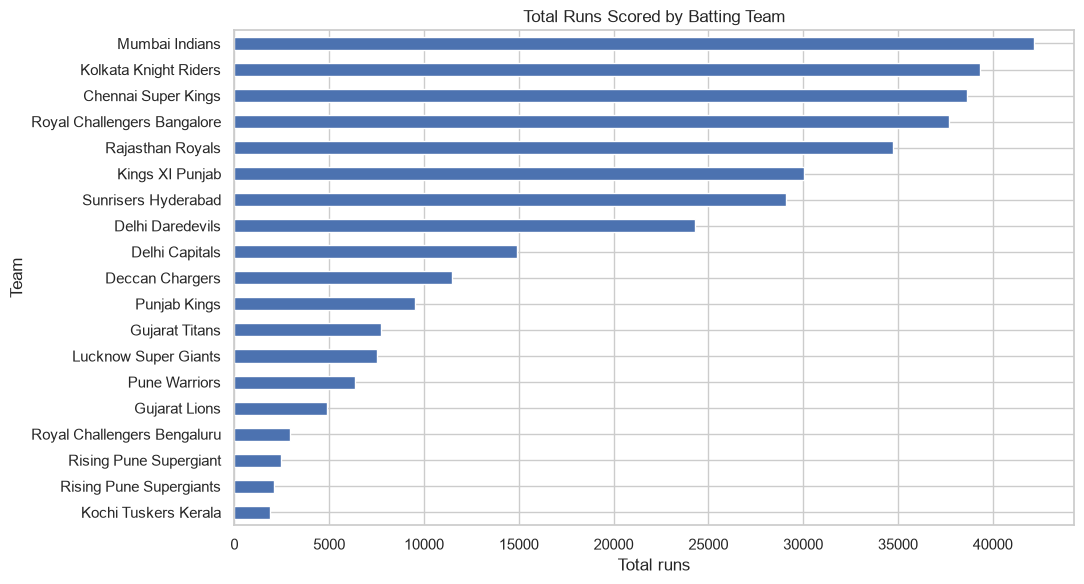

,average_innings_score
batting_team,
Royal Challengers Bengaluru,195.33
Gujarat Titans,172.38
Lucknow Super Giants,170.68
Punjab Kings,170.29
Delhi Capitals,163.74
Chennai Super Kings,162.99
Gujarat Lions,162.07
Mumbai Indians,161.59
Sunrisers Hyderabad,159.73


In [6]:
team_runs = deliveries.groupby("batting_team")["total_runs"].sum().sort_values(ascending=False)
display(team_runs.rename("total_runs").to_frame())

plt.figure(figsize=(11, 6))
team_runs.sort_values().plot(kind="barh")
plt.title("Total Runs Scored by Batting Team")
plt.xlabel("Total runs")
plt.ylabel("Team")
plt.tight_layout()
plt.show()

runs_per_match = deliveries.groupby(["match_id", "batting_team"])["total_runs"].sum().reset_index()
avg_team_score = runs_per_match.groupby("batting_team")["total_runs"].mean().sort_values(ascending=False)
display(avg_team_score.rename("average_innings_score").to_frame().round(2))

,awards
player_of_match,
AB de Villiers,25
CH Gayle,22
RG Sharma,19
DA Warner,18
V Kohli,18
MS Dhoni,17
SR Watson,16
YK Pathan,16
RA Jadeja,16


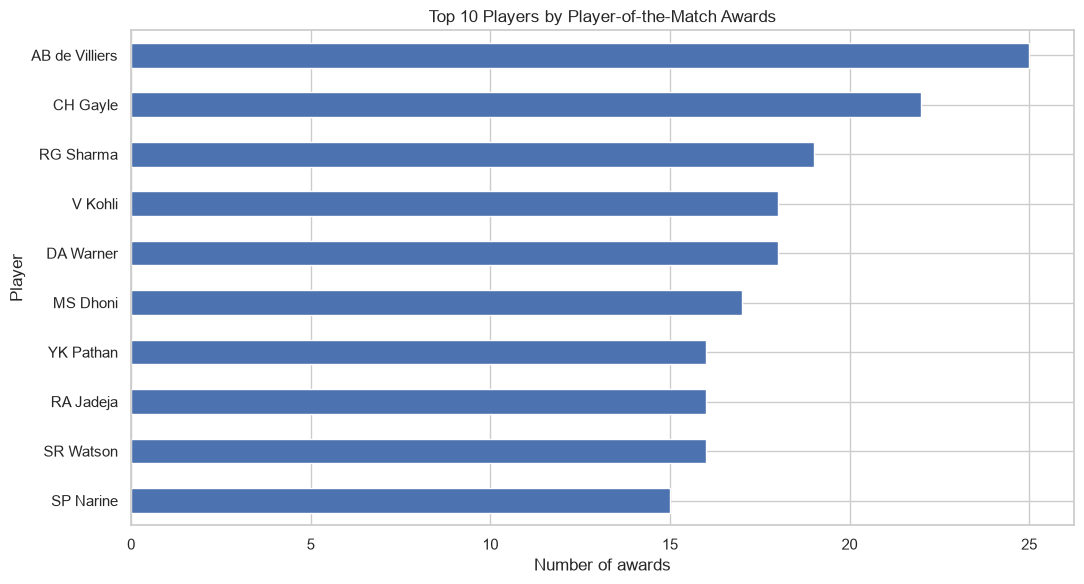

In [7]:
if "player_of_match" in matches.columns:
    awards = matches["player_of_match"].dropna().value_counts().head(10)
    display(awards.rename("awards").to_frame())
    plt.figure(figsize=(11, 6))
    awards.sort_values().plot(kind="barh")
    plt.title("Top 10 Players by Player-of-the-Match Awards")
    plt.xlabel("Number of awards")
    plt.ylabel("Player")
    plt.tight_layout()
    plt.show()
else:
    print("Column 'player_of_match' is not available in this dataset version.")

Toss winner also won the match in 50.83% of matches with known outcomes.


,count
toss_decision,
field,704
bat,391


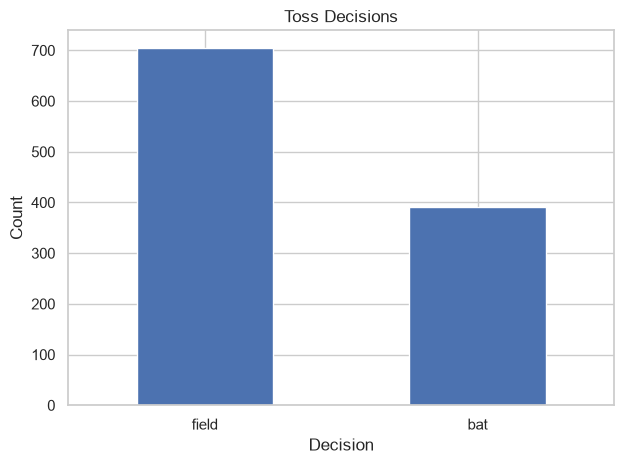

In [8]:
if "toss_winner" in matches.columns:
    valid_toss = matches.dropna(subset=["toss_winner", "winner"])
    toss_match_win_rate = (valid_toss["toss_winner"] == valid_toss["winner"]).mean() * 100
    print(f"Toss winner also won the match in {toss_match_win_rate:.2f}% of matches with known outcomes.")

if "toss_decision" in matches.columns:
    display(matches["toss_decision"].value_counts().rename("count").to_frame())
    matches["toss_decision"].value_counts().plot(kind="bar")
    plt.title("Toss Decisions")
    plt.xlabel("Decision")
    plt.ylabel("Count")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [9]:
print("PROJECT FINDINGS")
print("=" * 55)
if len(top_run_scorers):
    print(f"Top run scorer in this dataset: {top_run_scorers.iloc[0]['batter']} "
          f"({int(top_run_scorers.iloc[0]['runs'])} runs).")
if len(team_wins):
    print(f"Team with most match wins: {team_wins.index[0]} ({int(team_wins.iloc[0])} wins).")
if len(team_runs):
    print(f"Team with most total runs: {team_runs.index[0]} ({int(team_runs.iloc[0])} runs).")
if "player_of_match" in matches.columns and matches["player_of_match"].notna().any():
    print(f"Most Player-of-the-Match awards: {matches['player_of_match'].value_counts().index[0]}.")
print("Use the tables and plots above as evidence in the final report.")

PROJECT FINDINGS
Top run scorer in this dataset: V Kohli (8014 runs).
Team with most match wins: Mumbai Indians (144 wins).
Team with most total runs: Mumbai Indians (42176 runs).
Most Player-of-the-Match awards: AB de Villiers.
Use the tables and plots above as evidence in the final report.
